In [1]:
!pip install geemap
!pip install cartopy
!pip install matplotlib
!pip install cartopy
!pip install earthengine-api

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 72.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 91.7 MB/s eta 0:00:00


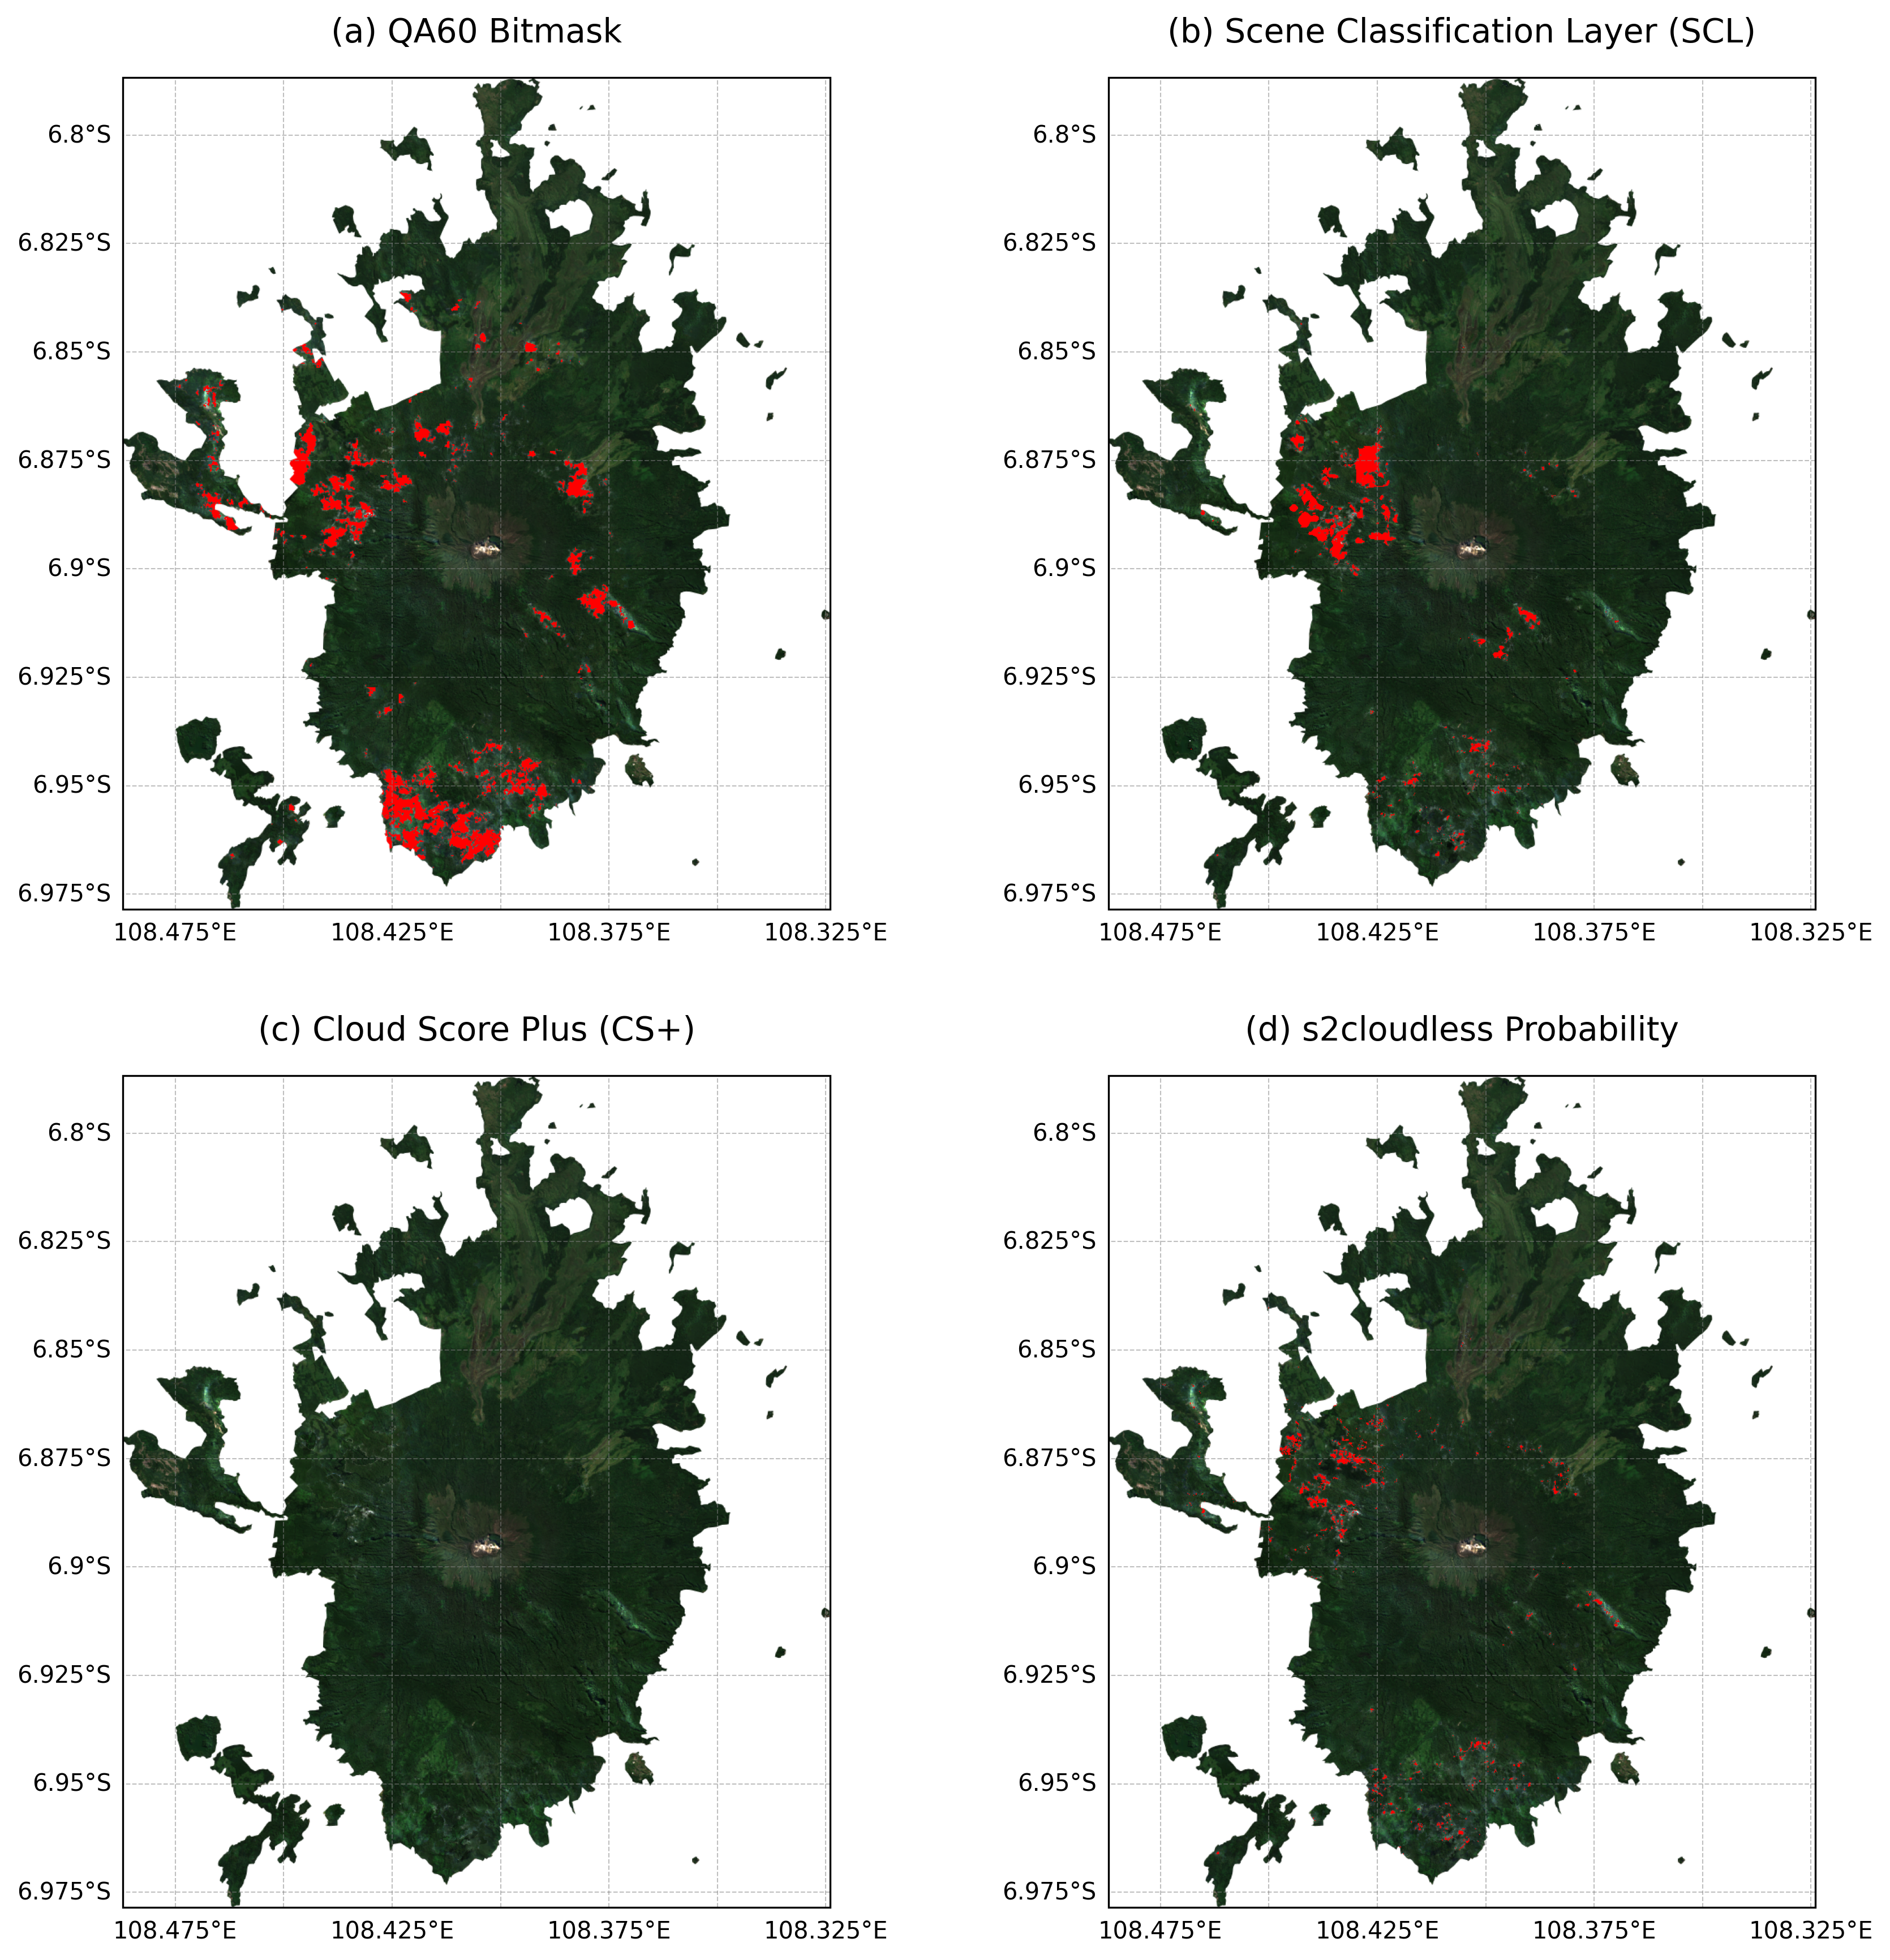

Visualisasi berhasil disimpan: Komparasi_Sisa_Awan_Cereme.png


In [9]:
import ee
import geemap.cartoee as cartoee
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.mpl.geoaxes import GeoAxes
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


cartoee.GeoAxes = GeoAxes
cartoee.GeoAxesSubplot = GeoAxes
cartoee.ccrs = ccrs

ee.Authenticate()
ee.Initialize(project='ee-defaniarman')

roi = ee.FeatureCollection("projects/ee-defaniarman/assets/cereme")
bounds = roi.geometry().bounds().getInfo()['coordinates'][0]
region_bbox = [bounds[0][0], bounds[0][1], bounds[2][0], bounds[2][1]]

start_date = '2025-05-01'
end_date = '2026-05-30'

s2_base = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
    .filterBounds(roi) \
    .filterDate(start_date, end_date) \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))

#Buat CS+ sebagai Basline
csPlus = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
s2_cs = s2_base.linkCollection(csPlus, ['cs_cdf'])

def apply_csplus(img):
    return img.updateMask(img.select('cs_cdf').gte(0.60))

# Citra komposit CS+ yang sangat bersih (sebagai acuan)
median_csplus = s2_cs.map(apply_csplus).median().divide(10000).select(['B4', 'B3', 'B2']).clip(roi)

# 3. FUNGSI HIGHLIGHT: Tandai sisa awan yang lolos dibanding CS+
def highlight_leftover_clouds(masked_collection):
    # Buat komposit dari algoritma yang sedang diuji
    median_algo = masked_collection.median().divide(10000).select(['B4', 'B3', 'B2']).clip(roi)

    # Hitung rata-rata kecerahan piksel (RGB)
    algo_brightness = median_algo.reduce(ee.Reducer.mean())
    cs_brightness = median_csplus.reduce(ee.Reducer.mean())

    # Logika Cerdas: Jika algoritma ini > 5% (0.05) lebih terang dari CS+,
    # berarti ada AWAN YANG LOLOS dari algoritma ini (CS+ berhasil menghapusnya)
    is_leftover = algo_brightness.subtract(cs_brightness).gt(0.05)

    # Buat kanvas warna merah
    red_color = ee.Image.constant([0.4, 0.0, 0.0]).rename(['B4', 'B3', 'B2']).clip(roi)

    # Timpa sisa awan tersebut dengan warna merah
    return median_algo.where(is_leftover, red_color)

# -- TERAPKAN ALGORITMA KE MASING-MASING METODE --

def apply_qa(img):
    qa = img.select('QA60')
    mask = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
    return img.updateMask(mask)
img_qa = highlight_leftover_clouds(s2_base.map(apply_qa))

def apply_scl(img):
    scl = img.select('SCL')
    mask = scl.neq(3).And(scl.neq(7)).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
    return img.updateMask(mask)
img_scl = highlight_leftover_clouds(s2_base.map(apply_scl))

# Untuk CS+ sendiri, ia akan dibandingkan dengan dirinya sendiri (tidak akan ada merah)
img_cs = highlight_leftover_clouds(s2_cs.map(apply_csplus))

s2c = ee.ImageCollection('COPERNICUS/S2_CLOUD_PROBABILITY')
def apply_s2c(img):
    return img.updateMask(img.select('probability').lt(65))
img_s2c = highlight_leftover_clouds(s2_base.linkCollection(s2c, ['probability']).map(apply_s2c))

# -- VISUALISASI --

images = [img_qa, img_scl, img_cs, img_s2c]
titles = [
    '(a) QA60 Bitmask',
    '(b) Scene Classification Layer (SCL)',
    '(c) Cloud Score Plus (CS+)',
    '(d) s2cloudless Probability'
]
vis_params = {'bands': ['B4', 'B3', 'B2'], 'min': 0.0, 'max': 0.25}

plt.rcParams['font.family'] = 'sans-serif'

fig = plt.figure(figsize=(14, 14), dpi=300)

for i in range(4):
    ax = fig.add_subplot(2, 2, i + 1, projection=ccrs.PlateCarree())

    cartoee.add_layer(ax, images[i], region=region_bbox, vis_params=vis_params)

    gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, linewidth=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}

    ax.set_title(titles[i], fontsize=14, loc='center', fontweight='normal', pad=15)

plt.subplots_adjust(wspace=0.15, hspace=0.20)

# Nama file diperbarui
output_file = "Komparasi_Sisa_Awan_Cereme.png"
plt.savefig(output_file, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Visualisasi berhasil disimpan: {output_file}")

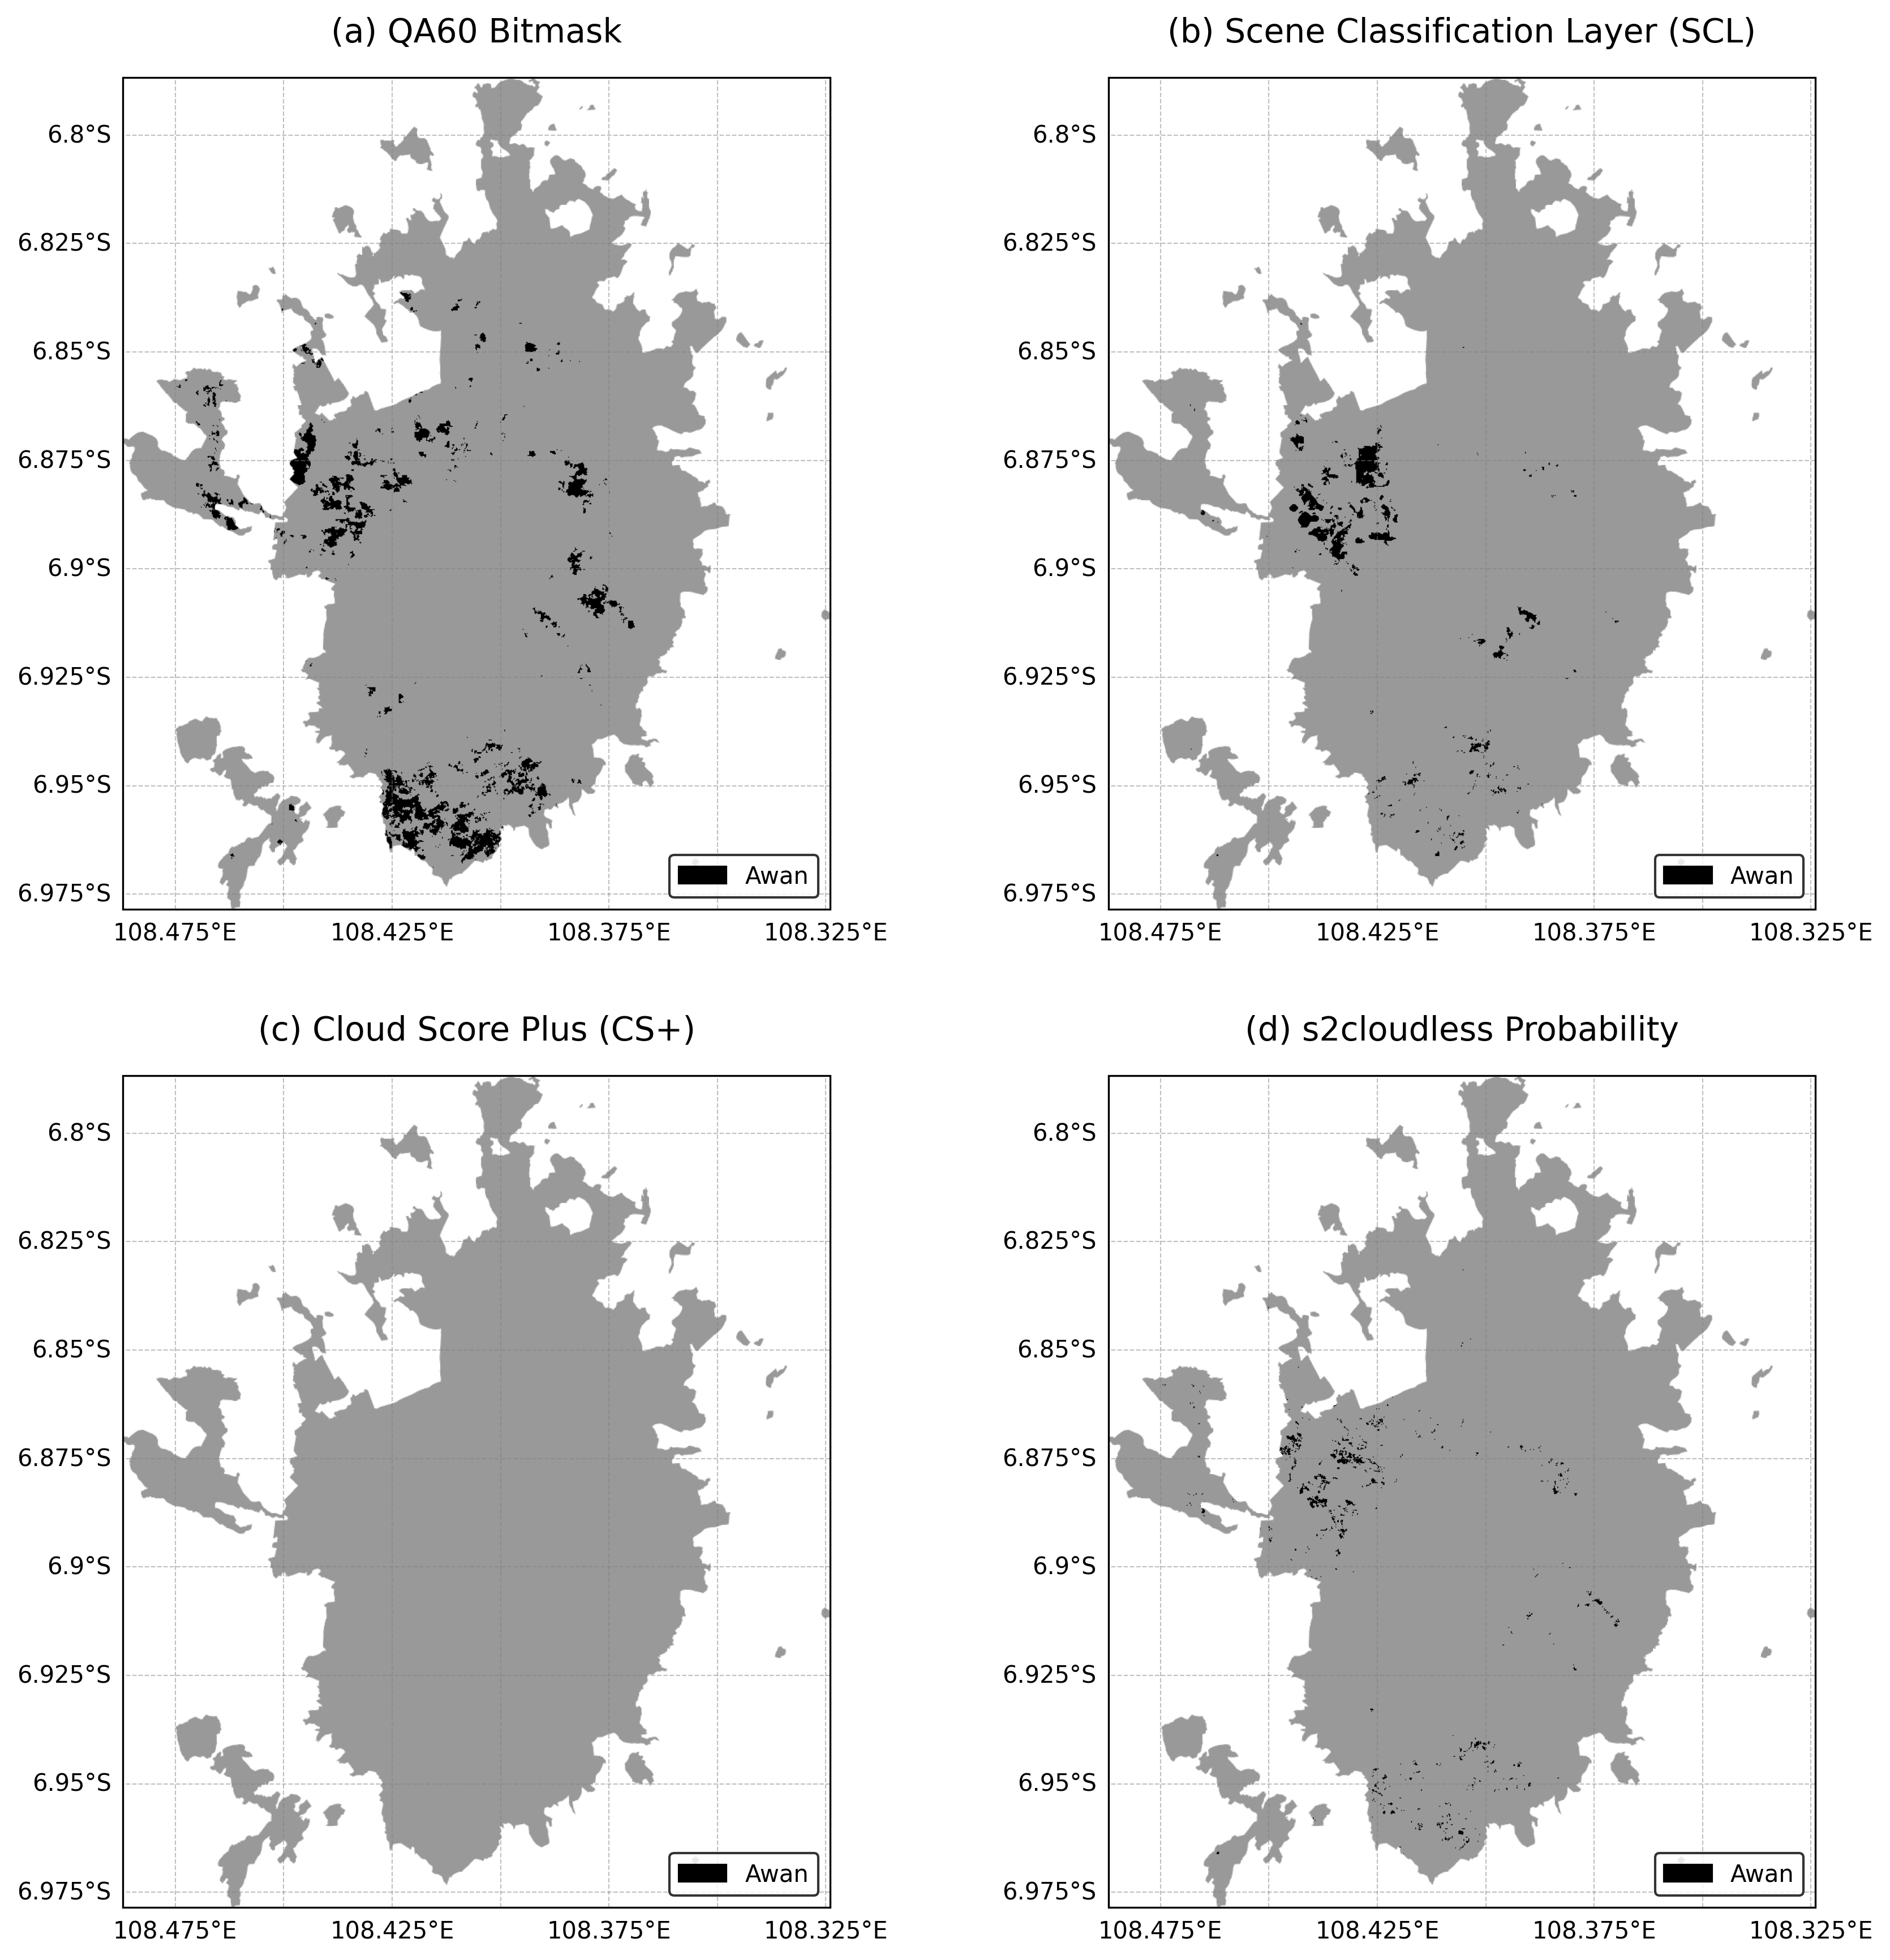

Visualisasi berhasil disimpan: Komparasi_Sisa_Awan_AbuItem_Cereme_with_Legend.png


In [13]:
import ee
import geemap.cartoee as cartoee
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.mpl.geoaxes import GeoAxes
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from matplotlib.patches import Patch

cartoee.GeoAxes = GeoAxes
cartoee.GeoAxesSubplot = GeoAxes
cartoee.ccrs = ccrs

ee.Initialize(project='ee-defaniarman')

roi = ee.FeatureCollection("projects/ee-defaniarman/assets/cereme")
bounds = roi.geometry().bounds().getInfo()['coordinates'][0]
region_bbox = [bounds[0][0], bounds[0][1], bounds[2][0], bounds[2][1]] # Corrected region_bbox

start_date = '2025-05-01'
end_date = '2026-05-30'

s2_base = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
    .filterBounds(roi) \
    .filterDate(start_date, end_date) \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))

csPlus = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
s2_cs = s2_base.linkCollection(csPlus, ['cs_cdf'])

def apply_csplus(img):
    return img.updateMask(img.select('cs_cdf').gte(0.60))

median_csplus = s2_cs.map(apply_csplus).median().divide(10000).select(['B4', 'B3', 'B2']).clip(roi)

def highlight_binary_clouds(masked_collection):
    median_algo = masked_collection.median().divide(10000).select(['B4', 'B3', 'B2']).clip(roi)
    algo_brightness = median_algo.reduce(ee.Reducer.mean())
    cs_brightness = median_csplus.reduce(ee.Reducer.mean())

    is_leftover = algo_brightness.subtract(cs_brightness).gt(0.05)
    gray_color = ee.Image.constant([0.15, 0.15, 0.15]).rename(['B4', 'B3', 'B2']).clip(roi)
    black_color = ee.Image.constant([0.0, 0.0, 0.0]).rename(['B4', 'B3', 'B2']).clip(roi)

    return gray_color.where(is_leftover, black_color)

def apply_qa(img):
    qa = img.select('QA60')
    mask = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
    return img.updateMask(mask)
img_qa = highlight_binary_clouds(s2_base.map(apply_qa))

def apply_scl(img):
    scl = img.select('SCL')
    mask = scl.neq(3).And(scl.neq(7)).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
    return img.updateMask(mask)
img_scl = highlight_binary_clouds(s2_base.map(apply_scl))

img_cs = highlight_binary_clouds(s2_cs.map(apply_csplus))

s2c = ee.ImageCollection('COPERNICUS/S2_CLOUD_PROBABILITY')
def apply_s2c(img):
    return img.updateMask(img.select('probability').lt(65))
img_s2c = highlight_binary_clouds(s2_base.linkCollection(s2c, ['probability']).map(apply_s2c))

images = [img_qa, img_scl, img_cs, img_s2c]
titles = [
    '(a) QA60 Bitmask',
    '(b) Scene Classification Layer (SCL)',
    '(c) Cloud Score Plus (CS+)',
    '(d) s2cloudless Probability'
]
vis_params = {'bands': ['B4', 'B3', 'B2'], 'min': 0.0, 'max': 0.25}

plt.rcParams['font.family'] = 'sans-serif'
fig = plt.figure(figsize=(14, 14), dpi=300)

for i in range(4):
    ax = fig.add_subplot(2, 2, i + 1, projection=ccrs.PlateCarree())
    cartoee.add_layer(ax, images[i], region=region_bbox, vis_params=vis_params)

    gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, linewidth=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}

    ax.set_title(titles[i], fontsize=14, loc='center', fontweight='normal', pad=15)

    # Add legend for 'awan' (cloud)
    cloud_patch = Patch(color='black', label='Awan')
    ax.legend(handles=[cloud_patch], loc='lower right', frameon=True, fontsize=10, facecolor='white', edgecolor='black')

plt.subplots_adjust(wspace=0.15, hspace=0.20)
output_file = "Komparasi_Sisa_Awan_AbuItem_Cereme_with_Legend.png"
plt.savefig(output_file, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Visualisasi berhasil disimpan: {output_file}")

### Plotting Unmasked Image

This plot shows the original Sentinel-2 image collection before any cloud masking algorithms are applied.

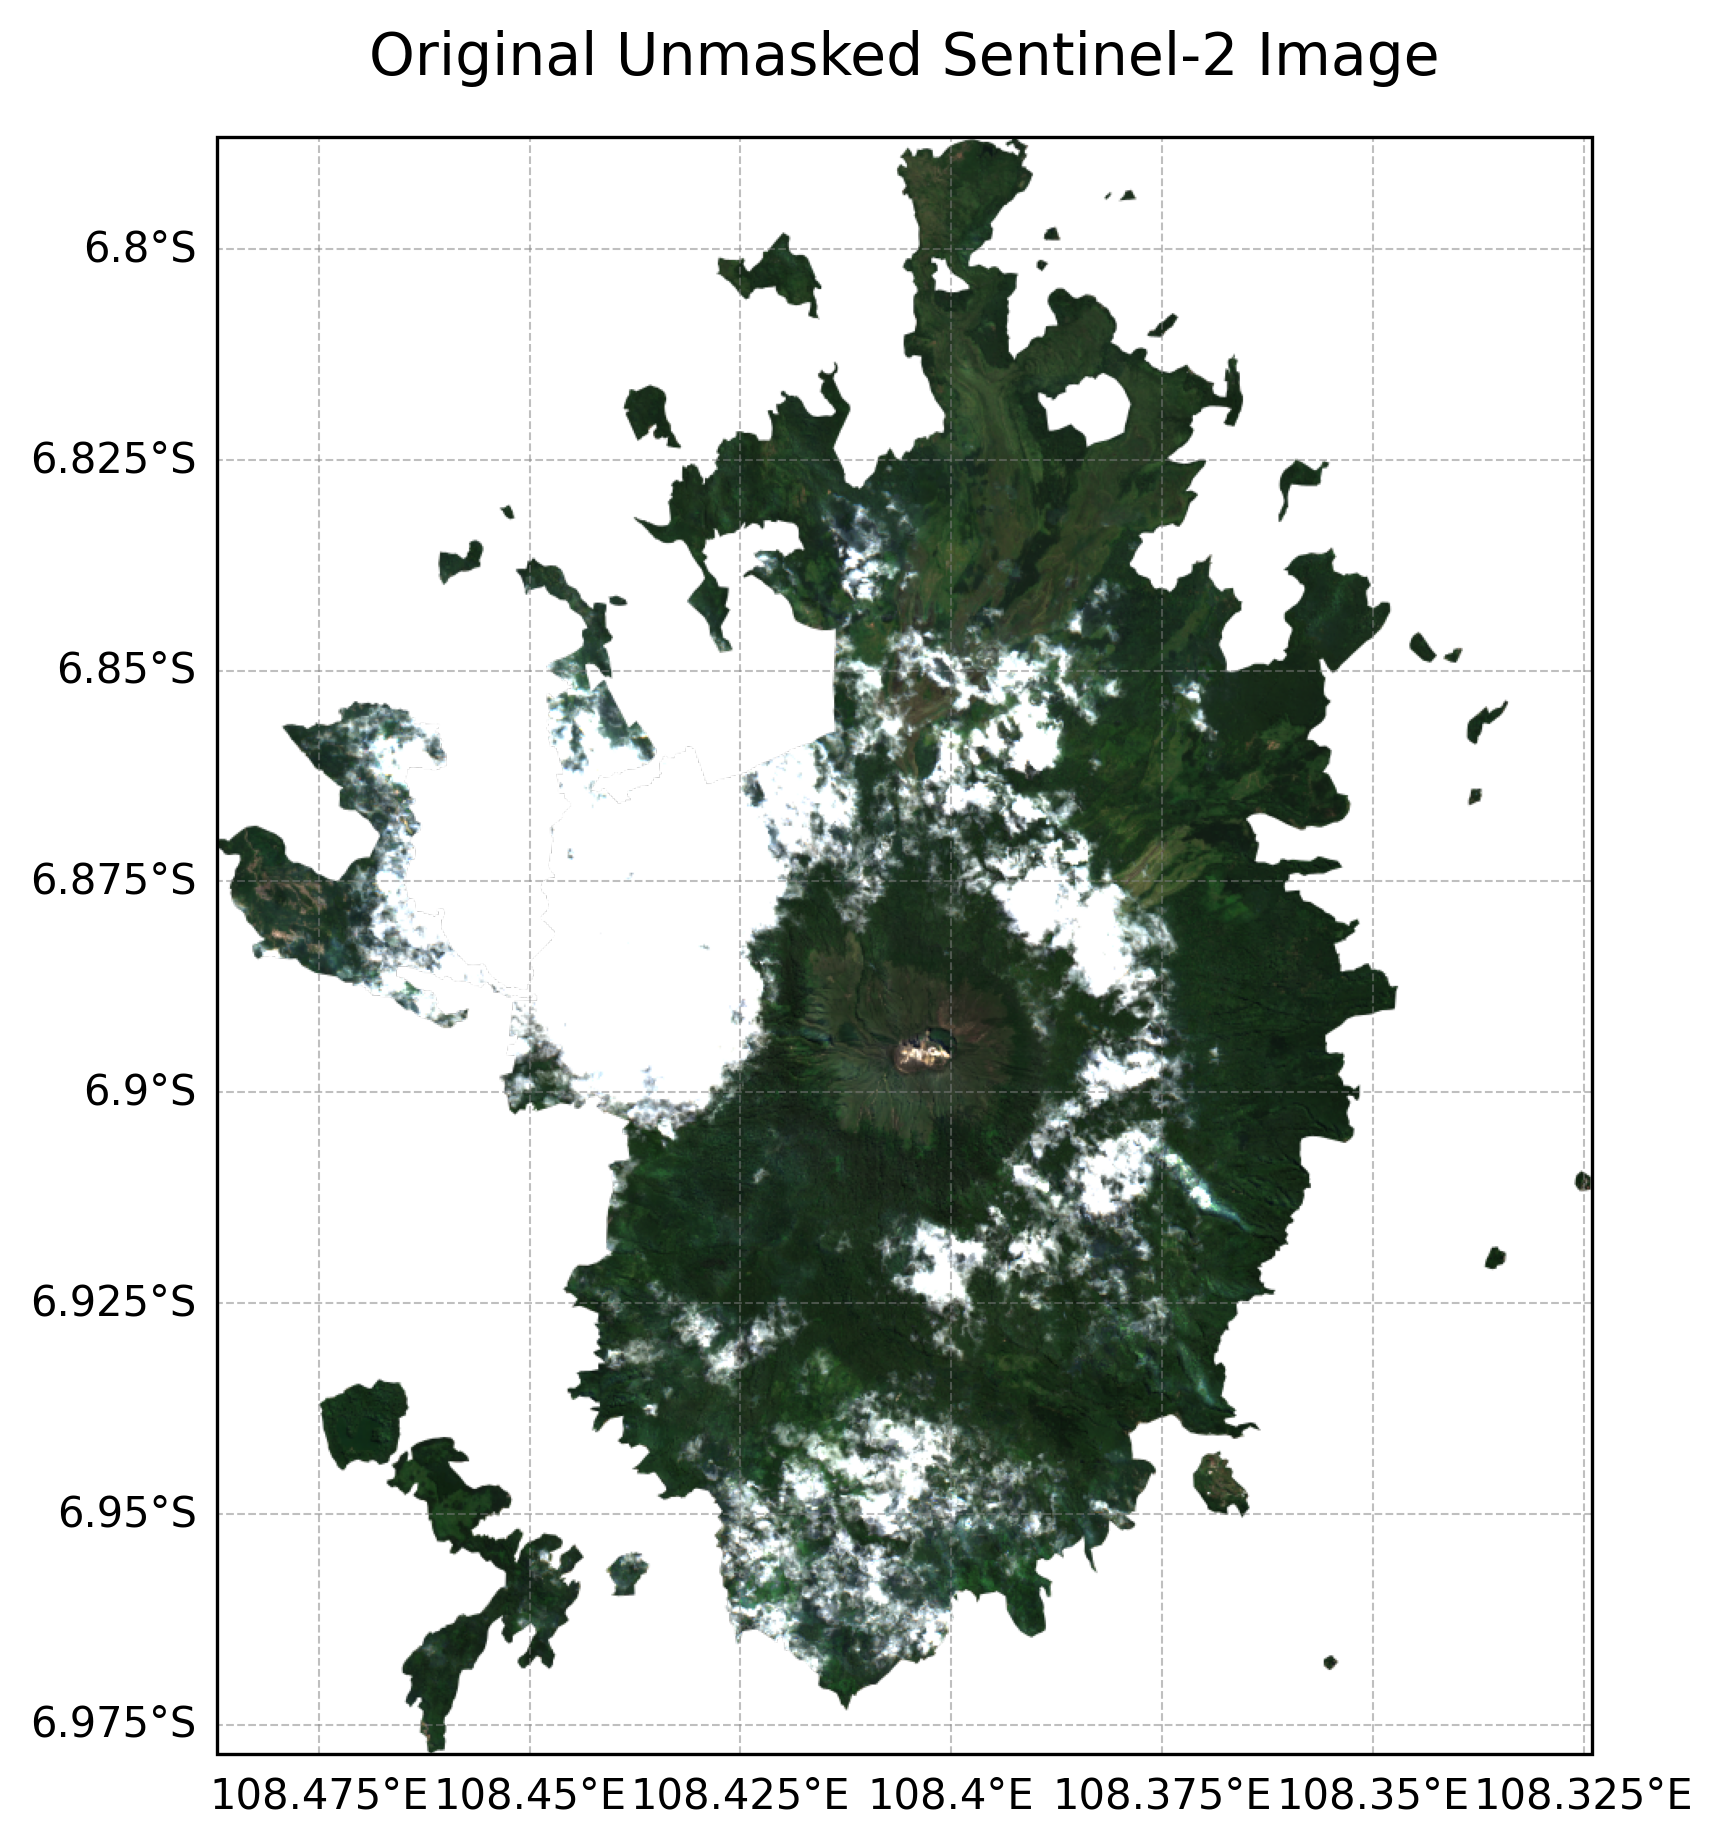

Unmasked visualization berhasil disimpan: Unmasked_Sentinel2_Cereme.png


In [14]:
fig = plt.figure(figsize=(7, 7), dpi=300)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

# Create a median composite from the base image collection (unmasked)
unmasked_image = s2_base.median().divide(10000).select(['B4', 'B3', 'B2']).clip(roi)

cartoee.add_layer(ax, unmasked_image, region=region_bbox, vis_params=vis_params)

gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, linewidth=0.5)
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}

ax.set_title('Original Unmasked Sentinel-2 Image', fontsize=14, loc='center', fontweight='normal', pad=15)

output_file_unmasked = "Unmasked_Sentinel2_Cereme.png"
plt.savefig(output_file_unmasked, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Unmasked visualization berhasil disimpan: {output_file_unmasked}")